# Module project: build a diffusion model that draws digits

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-4-ddpm-digits.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-5-generative/files/project-4-ddpm-digits.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/ddpm-digits` folder in the course files, to check your work.
- **Data**: MNIST handwritten digits (Hugging Face: ylecun/mnist). Source: [https://huggingface.co/datasets/ylecun/mnist](https://huggingface.co/datasets/ylecun/mnist) · about: [http://yann.lecun.com/exdb/mnist/](http://yann.lecun.com/exdb/mnist/) · licence: CC BY-SA 3.0. `data.py` downloads it the first time you run it and keeps it in `data/`: `mnist_test.npz`, `mnist_train.npz`, 11.0 MB.

In [ ]:
%pip install -q torch numpy pandas pyarrow pillow matplotlib

In the Build lesson, a *perfect* noise predictor turned pure noise back into data. For real images nobody can write that
predictor down, so a network has to learn it. In this project you build that network, a small U-Net, train it with
Algorithm 20.1 on handwritten digits, and generate new ones from pure noise with Algorithm 20.2.

You'll also prepare for the next module: the network is trained with the digit label, but the label is hidden 15% of the
time (section 20.4.2's trick). Today you generate with **no** label at all; tomorrow the same trained model will draw the
digit you ask for.

## What you'll build

```mermaid
flowchart LR
    A[digit x] --> B[add noise to<br/>a random step t]
    B --> C[U-Net:<br/>predict the noise]
    C --> D[squared error<br/>Algorithm 20.1]
    N[pure noise] --> S[500 denoising steps<br/>Algorithm 20.2]
    C -.-> S
    S --> X[new digit]
```

## Set up the project

```bash
mkdir ddpm-digits && cd ddpm-digits
python -m venv .venv && source .venv/bin/activate
pip install torch numpy pandas pyarrow pillow matplotlib
git init
```

```text
ddpm-digits/
    .gitignore
    README.md
    data.py
    diffusion.pt
    diffusion.py
    generate.py
    judge.pt
    judge.py
    requirements.txt
    train.py
    unet.py
```

In [ ]:
%%writefile requirements.txt
torch
numpy
pandas
pyarrow
pillow
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/*
!outputs/*.png
__pycache__/
*.pt
.venv/

Writing .gitignore


In [ ]:
%%writefile data.py
"""MNIST handwritten digits (70,000 images, 28x28) from the Hugging Face hub, as PyTorch tensors in [0, 1]."""
from pathlib import Path
import io
import numpy as np
import pandas as pd
import torch
from PIL import Image

URL = "https://huggingface.co/api/datasets/ylecun/mnist/parquet/mnist/{}/0.parquet"


def load(split):
    """split: 'train' (60,000) or 'test' (10,000). Returns images (N, 784) and labels (N,)."""
    cache = Path(f"data/mnist_{split}.npz")
    if not cache.exists():
        cache.parent.mkdir(exist_ok=True)
        table = pd.read_parquet(URL.format(split))
        X = np.stack([np.array(Image.open(io.BytesIO(img["bytes"]))) for img in table["image"]])
        np.savez_compressed(cache, X=X, y=table["label"].values)
    d = np.load(cache)
    return torch.tensor(d["X"].reshape(len(d["X"]), -1), dtype=torch.float32) / 255, torch.tensor(d["y"]).long()

Writing data.py


## Step 1: the network

The noise predictor `g(z_t, w, t)` takes a noisy image and the step number `t`, and returns an image-sized prediction of
the noise. A **U-Net** suits this job: it shrinks the image (28 → 14 → 7 pixels across) to see the overall shape, grows it
back to full size, and passes fine detail across through **skip connections**, the lines of the "U".

The network must know **how noisy** its input is, so the step `t` is turned into a vector with the sine-and-cosine
embedding used for positions in transformers (section 12.1.9), and added inside every block. The digit label gets its own
learned embedding, added to the same vector; label 10 means "no label".

In [ ]:
%%writefile unet.py
"""A small U-Net that predicts the noise in a noisy image, given the time step t and (optionally) a digit label."""
import math
import torch
from torch import nn

NULL = 10                                        # the "no label" token, for classifier-free guidance (section 20.4.2)


def time_embedding(t, dim=64):
    """Sinusoidal embedding of the step number, like the positional encoding of transformers (section 12.1.9)."""
    half = dim // 2
    freqs = torch.exp(-math.log(1000) * torch.arange(half) / half)
    angles = t[:, None].float() * freqs[None]
    return torch.cat([angles.sin(), angles.cos()], 1)


class Block(nn.Module):
    def __init__(self, c_in, c_out, emb=64):
        super().__init__()
        self.conv1, self.conv2 = nn.Conv2d(c_in, c_out, 3, padding=1), nn.Conv2d(c_out, c_out, 3, padding=1)
        self.norm1, self.norm2 = nn.GroupNorm(8, c_out), nn.GroupNorm(8, c_out)
        self.emb = nn.Linear(emb, c_out)
        self.act = nn.SiLU()

    def forward(self, x, e):
        h = self.act(self.norm1(self.conv1(x)))
        h = h + self.emb(e)[:, :, None, None]           # tell every pixel which step (and which digit) this is
        return self.act(self.norm2(self.conv2(h)))


class UNet(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.t_mlp = nn.Sequential(nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 64))
        self.label = nn.Embedding(11, 64)                # digits 0-9, and NULL
        self.down1, self.down2 = Block(1, c), Block(c, 2 * c)
        self.mid = Block(2 * c, 2 * c)
        self.up2, self.up1 = Block(4 * c, c), Block(2 * c, c)
        self.pool, self.upsample = nn.AvgPool2d(2), nn.Upsample(scale_factor=2)
        self.out = nn.Conv2d(c, 1, 1)

    def forward(self, x, t, y):
        e = self.t_mlp(time_embedding(t)) + self.label(y)
        h1 = self.down1(x, e)                            # 28 x 28
        h2 = self.down2(self.pool(h1), e)                # 14 x 14
        m = self.mid(self.pool(h2), e)                   # 7 x 7
        u2 = self.up2(torch.cat([self.upsample(m), h2], 1), e)     # skip connections: the "U"
        u1 = self.up1(torch.cat([self.upsample(u2), h1], 1), e)
        return self.out(u1)

Writing unet.py


## Step 2: the diffusion process

`diffusion.py` is chapter 20 in about 40 lines, in the book's notation, where `α_t` is the **product** of `(1 − β)`.

- `noisy` jumps straight to step `t` with the diffusion kernel (section 20.1.1): no need to run `t` steps.
- `loss` is Algorithm 20.1: pick a random step, add noise, predict it, squared error. 15% of the labels are replaced by
  "no label", so the same network learns both `p(x | digit)` and `p(x)`.
- `sample` is Algorithm 20.2, with the guidance mix of equation 20.60 already in place for the next module.

In [ ]:
%%writefile diffusion.py
"""Denoising diffusion (Bishop, chapter 20), in the book's notation: alpha_t is the PRODUCT of (1 - beta) up to t."""
import torch
from unet import NULL

T = 500
beta = torch.linspace(1e-4, 0.04, T)                     # the noise schedule beta_1 ... beta_T
alpha = torch.cumprod(1 - beta, 0)                       # alpha_t = prod (1 - beta_tau)  (Algorithm 20.1)


def noisy(x, t, eps):
    """z_t = sqrt(alpha_t) x + sqrt(1 - alpha_t) eps: jump straight to step t (the diffusion kernel, section 20.1.1)."""
    a = alpha[t][:, None, None, None]
    return a.sqrt() * x + (1 - a).sqrt() * eps


def loss(model, x, y, p_null=0.15):
    """Algorithm 20.1: noise an image to a random step, and train the network to predict the noise (section 20.2.4).
    With probability p_null the label is replaced by NULL, so one network learns both p(x | digit) and p(x)."""
    t = torch.randint(0, T, (len(x),))
    eps = torch.randn_like(x)
    y = torch.where(torch.rand(len(y)) < p_null, torch.full_like(y, NULL), y)
    return ((model(noisy(x, t, eps), t, y) - eps) ** 2).mean()


@torch.no_grad()
def sample(model, y, guidance=1.0, generator=None):
    """Algorithm 20.2, with classifier-free guidance (equation 20.60):
    predicted noise = guidance * eps(z, t, digit) + (1 - guidance) * eps(z, t, NULL)."""
    n = len(y)
    z = torch.randn(n, 1, 28, 28, generator=generator)
    null = torch.full_like(y, NULL)
    for t in range(T - 1, -1, -1):
        tt = torch.full((n,), t)
        if guidance == 0:
            eps = model(z, tt, null)
        elif guidance == 1:
            eps = model(z, tt, y)
        else:
            both = model(torch.cat([z, z]), torch.cat([tt, tt]), torch.cat([y, null]))
            eps = guidance * both[:n] + (1 - guidance) * both[n:]
        mean = (z - beta[t] / (1 - alpha[t]).sqrt() * eps) / (1 - beta[t]).sqrt()
        z = mean + beta[t].sqrt() * torch.randn(z.shape, generator=generator) if t > 0 else mean
    return z.clamp(-1, 1)

Writing diffusion.py


## Step 3: train

6,000 mini-batches of 128 images, with AdamW and a one-cycle schedule. On a laptop CPU this takes about half an hour; on a
GPU, a couple of minutes.

In [ ]:
%%writefile train.py
"""Train the diffusion model on MNIST: images scaled to [-1, 1], labels dropped 15% of the time."""
import argparse
import torch
from data import load
from unet import UNet
from diffusion import loss

ap = argparse.ArgumentParser()
ap.add_argument("--steps", type=int, default=6000)
args = ap.parse_args()
torch.manual_seed(0)
x, y = load("train")
x = x.reshape(-1, 1, 28, 28) * 2 - 1
model = UNet()
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
opt = torch.optim.AdamW(model.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=args.steps)
running = 0.0
for step in range(1, args.steps + 1):
    idx = torch.randint(0, len(x), (128,))
    l = loss(model, x[idx], y[idx])
    opt.zero_grad(); l.backward(); opt.step(); sched.step()
    running = 0.98 * running + 0.02 * l.item() if step > 1 else l.item()
    if step % 1000 == 0 or step == 1:
        print(f"step {step:5d}: noise-prediction loss {running:.4f}")
torch.save(model.state_dict(), "diffusion.pt")

Writing train.py


In [ ]:
!python train.py

237,217 parameters
step     1: noise-prediction loss 1.2349
step  1000: noise-prediction loss 0.0351
step  2000: noise-prediction loss 0.0291
step  3000: noise-prediction loss 0.0269
step  4000: noise-prediction loss 0.0249
step  5000: noise-prediction loss 0.0238
step  6000: noise-prediction loss 0.0238


The loss starts at about 1.2, which is what you get by predicting zero noise for noise with variance 1, and drops to
0.035 within the first 1,000 steps. After that it falls slowly, to 0.024. It never reaches zero, and it shouldn't: at
high noise levels, nobody can tell exactly which noise was added, so some error is unavoidable. Unlike the GAN, there is
no game to balance here: just one network and one loss going down.

## Step 4: a judge, then generate

As in the GAN project, a separate classifier, trained on real digits, judges the samples: how many is it confident about,
and which digits came out?

In [ ]:
%%writefile judge.py
"""A separate digit classifier, the 'judge': it scores how recognizable generated digits are, and which digit each is."""
import torch
import torch.nn.functional as F
from torch import nn
from data import load


def judge_net():
    return nn.Sequential(nn.Unflatten(1, (1, 28, 28)), nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 49, 10))


if __name__ == "__main__":
    torch.manual_seed(0)
    x, y = load("train"); xt, yt = load("test")
    net = judge_net(); opt = torch.optim.Adam(net.parameters(), 1e-3)
    for epoch in range(2):
        order = torch.randperm(len(x))
        for s in range(0, len(x), 128):
            i = order[s:s + 128]
            l = F.cross_entropy(net(x[i] * 2 - 1), y[i]); opt.zero_grad(); l.backward(); opt.step()
    with torch.no_grad():
        acc = (net(xt * 2 - 1).argmax(1) == yt).float().mean().item()
    print(f"judge accuracy on real test digits: {acc:.3f}")
    torch.save(net.state_dict(), "judge.pt")

Writing judge.py


In [ ]:
!python judge.py

judge accuracy on real test digits: 0.987


In [ ]:
%%writefile generate.py
"""Generate 100 digits with NO label (the unconditional model), and let the judge score them."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from unet import UNet, NULL
from diffusion import sample
from judge import judge_net

model = UNet(); model.load_state_dict(torch.load("diffusion.pt")); model.eval()
judge = judge_net(); judge.load_state_dict(torch.load("judge.pt")); judge.eval()
imgs = sample(model, torch.full((100,), NULL), guidance=0, generator=torch.Generator().manual_seed(0))
with torch.no_grad():
    p = torch.softmax(judge(imgs.reshape(100, -1)), 1)
conf, digit = p.max(1)
print(f"judge is at least 90% sure for {(conf > 0.9).float().mean():.0%} of the 100 generated digits")
print("which digits came out:", torch.bincount(digit, minlength=10).tolist(), "(10 each would be perfectly even)")
Path("outputs").mkdir(exist_ok=True)
fig, axes = plt.subplots(10, 10, figsize=(6, 6))
for img, ax in zip(imgs, axes.flat):
    ax.imshow(img[0], cmap="gray", vmin=-1, vmax=1); ax.axis("off")
fig.tight_layout(); fig.savefig("outputs/generated.png", dpi=90)
print("saved outputs/generated.png")

Writing generate.py


In [ ]:
!python generate.py

judge is at least 90% sure for 54% of the 100 generated digits
which digits came out: [9, 10, 9, 12, 9, 5, 7, 12, 12, 15] (10 each would be perfectly even)
saved outputs/generated.png


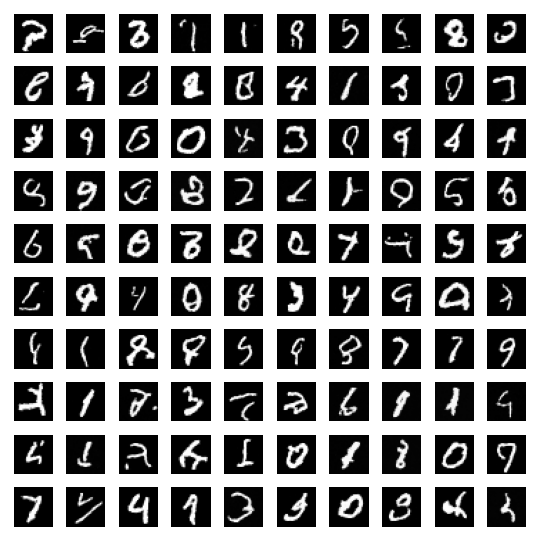

In [ ]:
from IPython.display import Image
Image('outputs/generated.png')

The judge reads real test digits correctly 98.7% of the time, so it's a fair referee. It is at least 90% sure about 54%
of the generated digits: most look like handwriting, and the rest are strokes caught halfway between two digits. All ten
digits come out, from 5 to 15 of each, close to the 10 each you'd expect by chance. That's a sign of no mode collapse:
the model didn't settle on a few easy digits, a common failure of GANs. This is a small network trained for half an hour
on a CPU; the next module shows how much the same network improves when you tell it which digit to draw.

## Step 5: write the README and publish

In [ ]:
%%writefile README.md
# Diffusion model that draws handwritten digits

A denoising diffusion model (DDPM) written from scratch in PyTorch: a small U-Net with time and label embeddings,
trained on MNIST to predict the noise added to an image, then used to turn pure noise into new digits in 500 steps.

![generated digits](outputs/generated.png)

## Results (100 digits generated with no label)

| measure | value |
|---|---|
| U-Net parameters | 237,217 |
| training | 6,000 steps of 128 images, about 30 minutes on a laptop CPU |
| final noise-prediction loss | 0.024 (1.23 at the start) |
| judge accuracy on real test digits | 98.7% |
| generated digits the judge is at least 90% sure about | 54% |
| digits per class among the 100 samples | 5 to 15 (10 would be perfectly even) |

## Run it

```bash
pip install -r requirements.txt
python train.py      # saves diffusion.pt
python judge.py      # saves judge.pt, a CNN that scores the samples
python generate.py   # saves outputs/generated.png
```

## What I learned

- Training a diffusion model is simple: pick a random noise level, add noise in one step (the closed-form kernel),
  and train the network to predict that noise with a squared error.
- The network has to be told how noisy its input is; the time embedding does that.
- Sampling is the slow part: 500 network passes per image, against one per example in training.
- Hiding the label 15% of the time during training gives one network that can draw with or without a label.

Based on chapter 20 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Denoising diffusion model that draws MNIST digits"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/ddpm-digits.git
git push -u origin main
```

## Make it yours

- **Watch a digit appear.** Save `z` every 50 steps while sampling one digit and draw the sequence, from noise to digit.
- **Fewer steps.** Sample with only every 5th step (and the matching betas). How much faster is it, and how much worse?
- **Train longer.** On a GPU, train for 30,000 steps. How do "judge sure" and the look of the digits change?
- **Clothes.** Train the same model on Fashion-MNIST and compare its samples with your GAN's, using your GAN judge.

## On your CV

> **Denoising diffusion model** (PyTorch): built a 237k-parameter U-Net with time and label embeddings, trained it with
> the DDPM noise-prediction loss on MNIST, and sampled with 500 reverse steps; generated digits cover all ten classes
> (5 to 15 of each per 100) and a separate CNN judge (98.7% on real digits) is confident on 54% of them.
> github.com/YOUR-USERNAME/ddpm-digits

## Check yourself

- [ ] You can explain why the network needs to know the step `t`.
- [ ] You can write the training loss of Algorithm 20.1 from memory.
- [ ] You can explain why sampling takes 500 network passes but training needs only one per example.